# Day 5 roadmap
1. Statistical estimates
Understand how plots summarize data using means and other statistics.

2. Error bars and confidence intervals
Understand uncertainty around estimated values.

3. Regression plots
Learn regplot() and lmplot() and interpret trends.

# Imports and Dataset

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("tips")

df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


# Part 1 — Statistical estimates with sns.barplot()
You've already used `barplot()` on Day 2. Today, we'll go deeper into the statistics behind it rather than repeat the basics.

**Explanation**
By default, `sns.barplot()` calculates the mean of a numerical variable for each category and displays that estimate as a bar. By default, it also shows a 95% confidence interval for the estimated mean.

For example, this code estimates the average tip for each day:

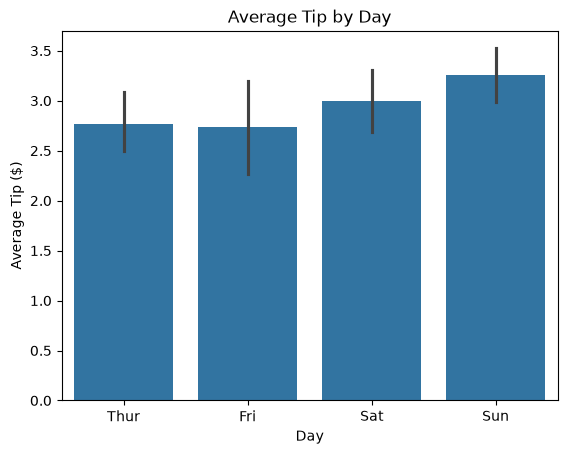

In [16]:
sns.barplot(data=df, x="day", y="tip")

plt.title("Average Tip by Day")
plt.xlabel("Day")
plt.ylabel("Average Tip ($)")

plt.show()

The bar height represents the estimated mean tip for that day—not the number of customers.

Notice the vertical lines extending from the bars. Those are **error bars**, which bring us to the next concept.

**Question:**\
Suppose customers on Thursday tip `$1, $2, $3`, and customers on Friday tip `$2, $4, $6`.

What will sns.barplot() show for these two groups?\
A. Thursday: `$6`, Friday: `$12`, because it sums the tips.\
B. Thursday: `$2`, Friday: `$4`, because it calculates the mean.\
C. Thursday: 3, Friday: 3, because it counts the customers.

**Answer:**\
The answer is B.\
`sns.barplot()` calculates the mean (average) tip for each day by default.
Let's verify the calculations:
Thursday:
$$\text{Mean}=\frac{1+2+3}{3}=\$2$$

Friday:
$$\text{Mean}=\frac{2+4+6}{3}=\$4$$

So the bars will have heights of `$2` for Thursday and `$4` for Friday.

# Part 2 — Understanding confidence intervals
A barplot's height is an estimate of the mean. But how certain are we about that estimate?

**A confidence interval (CI)** represents uncertainty around an estimated value.

By default, Seaborn's `barplot()` displays a 95% confidence interval, estimated using bootstrapping.
- **Bar height:** Estimated mean tip.
- **Error bars:** Uncertainty around the estimated mean.
- **Narrower interval:** Generally indicates a more precise estimate.
- **Wider interval:** Generally indicates more uncertainty.

A confidence interval is not a range containing 95% of individual tips. It describes uncertainty in the estimated mean.

**Question:**\
Suppose two groups have the same average tip, but one group has much wider confidence intervals.

What does that suggest?\
A. The group with wider intervals necessarily has a higher average tip.\
B. The group with wider intervals has greater uncertainty around its estimated mean.\
C. Both groups must have exactly the same individual tip amounts.

**Answer:**\
The answer is B.\
A group with wider confidence intervals has greater uncertainty around its estimated mean.

**Why?**\
Imagine two groups have the same average tip of $3:

<div align="center">
	<img src="../Images/Seaborn_15.png" style="border-radius: 8px; max-width: 80%;">
</div>

The average is identical in both groups, but the second estimate is less precise. The interval width can be affected by sample size and variability in the data.

**Remember:** A 95% confidence interval is about uncertainty in the estimated mean, not a range that must contain 95% of individual tips.

## Practice reading error bars

```python
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("tips")

sns.barplot(data=df, x="day", y="tip")

plt.title("Average Tip by Day")
plt.xlabel("Day")
plt.ylabel("Average Tip ($)")
plt.show()
```
Before running it, make a prediction:

**Question:**\
If Friday has a taller bar than Thursday, what does that mean?\
A. Friday has more customers than Thursday.\
B. The average tip on Friday is higher than on Thursday.\
C. Every customer on Friday tipped more than every customer on Thursday.

**Answer:**\
The answer is B.\
If Friday has a taller bar than Thursday in this plot, it means the average tip on Friday is higher than the average tip on Thursday.

**Why?**
- X-axis (day): Categories such as Thur, Fri, Sat, and Sun.
- Y-axis (tip): Tip amounts.
- Bar height: The mean tip for that day.
- Error bars: The uncertainty around the estimated mean, shown as 95% confidence intervals by default.

Remember, a taller bar does not necessarily mean more customers or that every customer tipped more.

## Customize confidence intervals
Seaborn lets you control the error bars using the errorbar parameter.

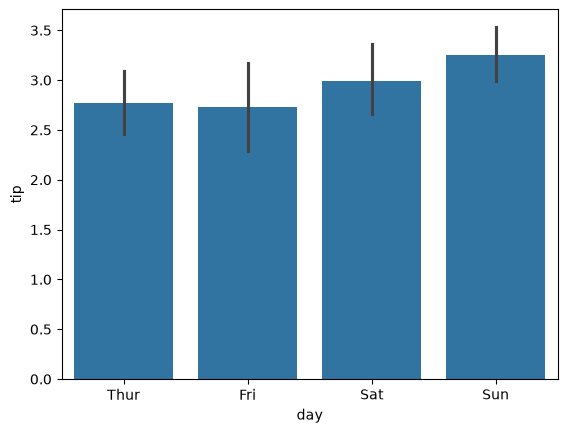

In [17]:
# Default: 95% confidence interval
sns.barplot(data=df, x="day", y="tip")

plt.show()

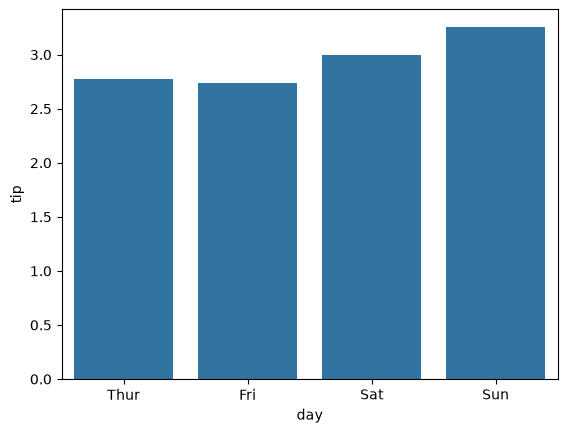

In [18]:
# Hide error bars
sns.barplot(data=df, x="day", y="tip", errorbar=None)

plt.show()

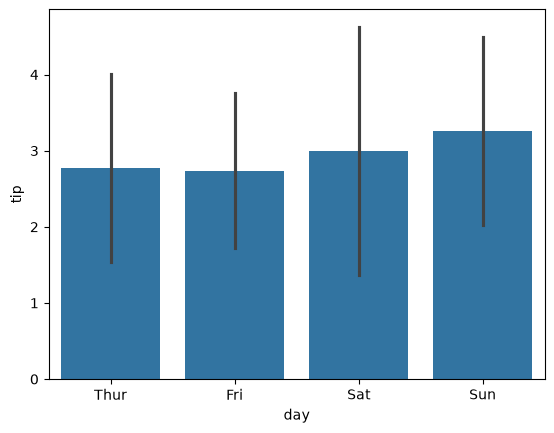

In [19]:
# Show standard deviation instead
sns.barplot(data=df, x="day", y="tip", errorbar="sd")

plt.show()

- errorbar=("ci", 95) — 95% confidence interval.
- errorbar=None — no error bars.
- errorbar="sd" — standard deviation, which describes variability in the observations rather than uncertainty in the estimated mean.

# Part 3 — Statistical estimates with sns.regplot()
Now let's move to another important part of statistical visualization: **regression plots**. These help us understand relationships between numerical variables.

Before we write code, predict this:

If `sns.regplot(data=df, x="total_bill", y="tip")` shows an upward-sloping regression line, what does that suggest?\

A. Larger bills tend to be associated with larger tips.\
B. Every customer with a larger bill always leaves a larger tip.\
C. Total bill and tip have no relationship.

**Answer:**\
The answer is A.\
An upward-sloping regression line suggests that **larger bills tend to be associated with larger tips**. This is a positive relationship between `total_bill` and `tip`.

It does not mean every customer with a larger bill leaves a larger tip. Individual customers can behave differently.

## Regression plots
1. Explanation\
Seaborn's regplot() displays two things:
- Scatter points: Individual observations from the dataset.
- Regression line: A line representing the overall linear trend.
- Shaded region: The default 95% confidence interval around the estimated regression line.

2. Code

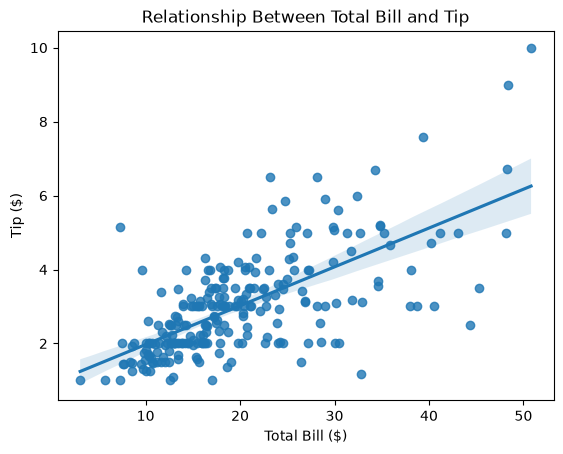

In [20]:
sns.regplot(data=df, x="total_bill", y="tip")

plt.title("Relationship Between Total Bill and Tip")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.show()

**Question:**\
What do the individual dots in sns.regplot() represent?

A. The average tip for each day.\
B. Individual observations of total bill and tip.\
C. The confidence interval

**Answer:**\
The answer is B.\
Individual observations of total bill and tip.
In Seaborn's `sns.regplot()`, each dot represents one observation from the dataset.

Here's how to read the plot:
- **X-axis:** The customer's total bill.
- **Y-axis:** The customer's tip.
- **Each dot:** One customer's bill and tip combination.
- **Regression line:** The overall linear trend.
- **Shaded region:** The default 95% confidence interval around the estimated regression line.

For example, a dot at `(20, 4)` represents a customer with a total bill of `$20` and a tip of `$4`.

## lmplot()
Both `regplot()` and `lmplot()` help visualize relationships and regression trends, but `lmplot()` is especially useful when you want to compare groups using separate panels.

For example:

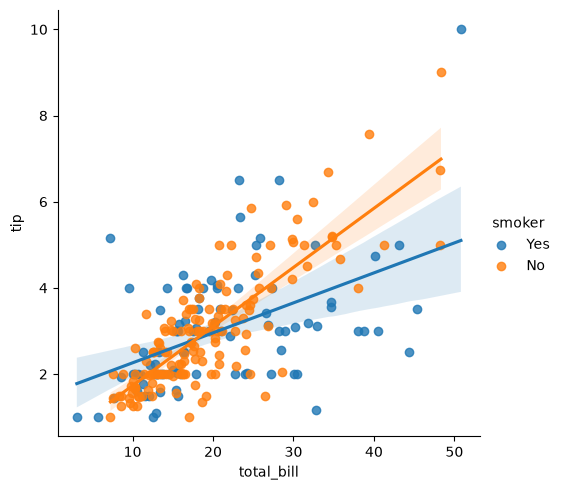

In [22]:
sns.lmplot(
    data=df,
    x="total_bill",
    y="tip",
    hue="smoker"
)

plt.show()

This creates separate regression lines for smokers and non-smokers, distinguished by color.

**Observation:**
- Dots: Individual customers.
- Different colors: Smokers and non-smokers.
- Regression lines: The overall bill–tip trend for each group.
- Shaded regions: Confidence intervals around the estimated regression lines.

**Question:**\
What does hue="smoker" do here?

A. It creates a separate plot for each meal time.\
B. It colors the groups differently and fits a regression line for each smoker category.\
C. It removes all non-smokers from the dataset.

**Answer:**\
The answer is B.\
In `sns.lmplot()`, `hue="smoker"` assigns different colors to the smoker categories and fits a regression line for each category.

## regplot() vs. lmplot()
| Feature | regplot() | lmplot() |
| :--- | :--- | :--- |
|Main purpose | Plot a regression relationship | Plot regression relationships with grouping and faceting |
|hue support | No direct hue parameter | Yes |
| Separate panels with col or row | No | Yes |
| Returns | Matplotlib Axes | Seaborn FacetGrid |

**Question:**\
What happens when you add col="time" to lmplot()?
```python
sns.lmplot(
    data=df,
    x="total_bill",
    y="tip",
    col="time"
)
```
A. It creates separate panels for Lunch and Dinner.\
B. It colors Lunch and Dinner differently in one panel.\
C. It removes the regression lines

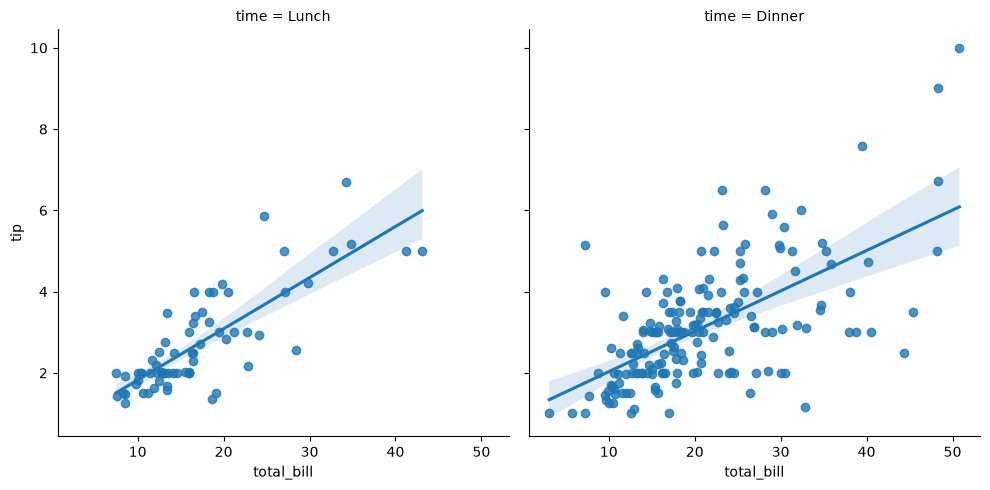

In [23]:
sns.lmplot(
    data=df,
    x="total_bill",
    y="tip",
    col="time"
)

**Answer:**
The answer is A.\
`col="time"` creates **separate panels for Lunch and Dinner**, allowing you to compare the relationship between the total bill and tip at each meal time.

**The important distinction:**
- `hue="time"` → distinguishes Lunch and Dinner using colors in the same panel.
- `col="time"` → creates separate side-by-side panels.
- `row="sex", col="time"` → creates panels for combinations of sex and meal time.

# Day 5 — Quick Revision Quiz

In [26]:

from IPython.display import HTML, display

quiz_html = """
<div id="seaborn-quiz" style="font-family:Arial,sans-serif; line-height:1.6;">
    <p>Test your understanding of statistical visualization.</p>

    <div class="question" data-answer="b">
        <p><b>1. What does the height of a default Seaborn barplot represent?</b></p>
        <label><input type="radio" name="q1" value="a"> A. The number of observations</label><br>
        <label><input type="radio" name="q1" value="b"> B. The mean of the numerical variable</label><br>
        <label><input type="radio" name="q1" value="c"> C. The maximum value</label>
        <p class="feedback"></p>
    </div>

    <hr>

    <div class="question" data-answer="b">
        <p><b>2. What does <code>errorbar=None</code> do in <code>sns.barplot()</code>?</b></p>
        <label><input type="radio" name="q2" value="a"> A. Removes the bars</label><br>
        <label><input type="radio" name="q2" value="b"> B. Hides the error bars</label><br>
        <label><input type="radio" name="q2" value="c"> C. Shows standard deviation</label>
        <p class="feedback"></p>
    </div>

    <hr>

    <div class="question" data-answer="c">
        <p><b>3. Which parameter creates separate panels in <code>sns.lmplot()</code>?</b></p>
        <label><input type="radio" name="q3" value="a"> A. <code>hue</code></label><br>
        <label><input type="radio" name="q3" value="b"> B. <code>style</code></label><br>
        <label><input type="radio" name="q3" value="c"> C. <code>col</code></label>
        <p class="feedback"></p>
    </div>

    <br>
    <button type="button" id="check-answers"
        style="padding:10px 18px; background:#2563eb; color:white;
        border:none; border-radius:6px; cursor:pointer;">
        Check Answers
    </button>

    <button type="button" id="reset-quiz"
        style="padding:10px 18px; margin-left:8px; border:1px solid #999;
        border-radius:6px; cursor:pointer;">
        Reset
    </button>

    <h3 id="score"></h3>
</div>

<script>
(function () {
    const quiz = document.getElementById("seaborn-quiz");
    if (quiz.dataset.initialized) return;
    quiz.dataset.initialized = "true";

    const explanations = [
        "A barplot displays the estimated mean by default for each category.",
        "errorbar=None hides the uncertainty/error indicators, not the bars or their means.",
        "col creates separate panels for categories of a variable in lmplot."
    ];

    const questions = Array.from(quiz.querySelectorAll(".question"));

    quiz.querySelector("#check-answers").addEventListener("click", function () {
        let score = 0;
        let unanswered = 0;

        questions.forEach((question, i) => {
            const selected = question.querySelector("input:checked");
            const feedback = question.querySelector(".feedback");
            const correct = question.dataset.answer;

            if (!selected) {
                unanswered++;
                feedback.textContent = "Please select an answer.";
                feedback.style.color = "#b45309";
            } else if (selected.value === correct) {
                score++;
                feedback.textContent = "Correct! " + explanations[i];
                feedback.style.color = "#15803d";
            } else {
                feedback.textContent = "Not quite. " + explanations[i];
                feedback.style.color = "#b91c1c";
            }
        });

        quiz.querySelector("#score").textContent =
            "Your score: " + score + "/3" +
            (unanswered ? " — " + unanswered + " question(s) unanswered." : "");
    });

    quiz.querySelector("#reset-quiz").addEventListener("click", function () {
        quiz.querySelectorAll("input[type=radio]").forEach(input => {
            input.checked = false;
        });
        quiz.querySelectorAll(".feedback").forEach(p => {
            p.textContent = "";
        });
        quiz.querySelector("#score").textContent = "";
    });
})();
</script>
"""

display(HTML(quiz_html))


# Mini project: Seaborn Statistical Dashboard

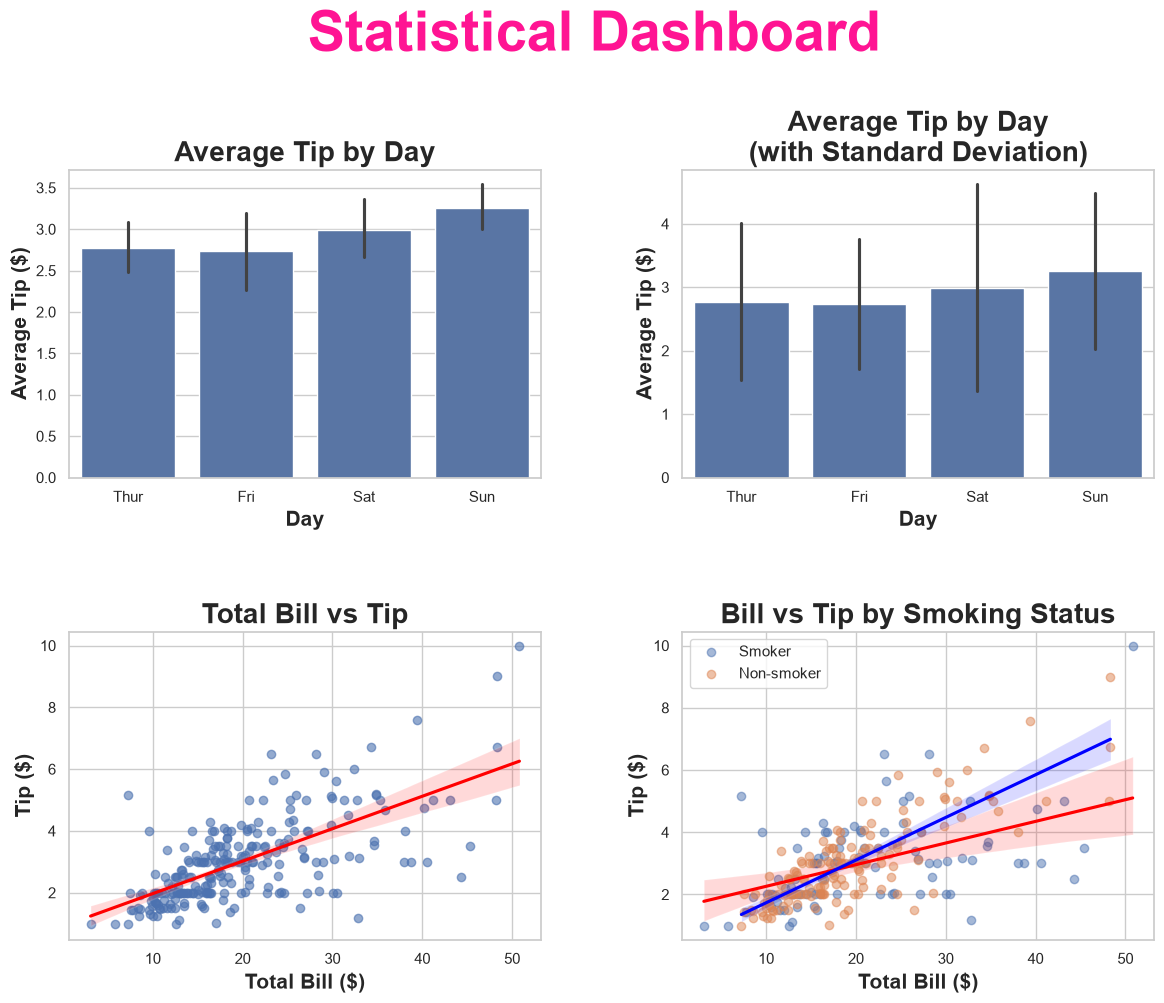

In [70]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

fig.suptitle(
    "Statistical Dashboard",
    fontsize=40,
    fontweight="bold",
    color="deeppink",
    y=1.04
)

# Plot 1: Default 95% confidence interval
sns.barplot(
    data=df,
    x="day",
    y="tip",
    ax=ax[0, 0]
)

ax[0, 0].set_title(
    "Average Tip by Day", fontsize=20, fontweight="bold"
)
ax[0, 0].set_xlabel("Day", fontsize=15, fontweight="bold")
ax[0, 0].set_ylabel("Average Tip ($)", fontsize=15, fontweight="bold")


# Plot 2: Standard deviation
sns.barplot(
    data=df,
    x="day",
    y="tip",
    errorbar="sd",
    ax=ax[0, 1]
)

ax[0, 1].set_title(
    "Average Tip by Day\n(with Standard Deviation)",
    fontsize=20, fontweight="bold"
)
ax[0, 1].set_xlabel("Day", fontsize=15, fontweight="bold")
ax[0, 1].set_ylabel("Average Tip ($)", fontsize=15, fontweight="bold")


# Plot 3: Total bill vs tip
sns.regplot(
    data=df,
    x="total_bill",
    y="tip",
    ax=ax[1, 0],
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

ax[1, 0].set_title(
    "Total Bill vs Tip", fontsize=20, fontweight="bold"
)
ax[1, 0].set_xlabel("Total Bill ($)", fontsize=15, fontweight="bold")
ax[1, 0].set_ylabel("Tip ($)", fontsize=15, fontweight="bold")


# Plot 4: Total bill vs tip by smoker group
sns.regplot(
    data=df[df["smoker"] == "Yes"],
    x="total_bill",
    y="tip",
    ax=ax[1, 1],
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"},
    label="Smoker"
)

sns.regplot(
    data=df[df["smoker"] == "No"],
    x="total_bill",
    y="tip",
    ax=ax[1, 1],
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "blue"},
    label="Non-smoker"
)

ax[1, 1].set_title(
    "Bill vs Tip by Smoking Status",
    fontsize=20,
    fontweight="bold"
)
ax[1, 1].set_xlabel("Total Bill ($)", fontsize=15, fontweight="bold")
ax[1, 1].set_ylabel("Tip ($)", fontsize=15, fontweight="bold")
ax[1, 1].legend()

# Adjust spacing and display
fig.subplots_adjust(
    hspace=0.5,
    wspace=0.3
)

plt.show()

**Important**\
Plot 4: The data is filtered into smokers (`"Yes"`) and non-smokers (`"No"`), then both regression plots are drawn on `ax[1, 1].`

Legend: Red represents smokers, and blue represents non-smokers.

**Remember:** `regplot()` supports the `ax` parameter, whereas `lmplot()` creates its own figure. Use `regplot()` when you want complete control over a Matplotlib subplot dashboard.